# HoneyBadger · Offline network-intrusion analysis

**Research question.** Using recorded, labeled network connections, how well can a simple, reproducible classifier separate *anomaly* from *normal* traffic? How much of that evidence covers the two services HoneyBadger emulates (SSH and HTTP)?

**Dataset.** [Network Intrusion Detection](https://www.kaggle.com/datasets/sampadab17/network-intrusion-detection) on Kaggle, published by Sampada Bhosale. Kaggle lists the license as *Unknown*, so use it for study and check the terms before redistributing. Two CSV files:

| File | What one row is | Label |
|---|---|---|
| `Train_data.csv` | one network connection, 41 features (KDD-style) | `class`: `normal` or `anomaly` |
| `Test_data.csv` | one network connection, the same 41 features | none |

**Scope.** This is an offline analysis of recorded data. It does not need Docker, the honeypot services or the attack simulator. HoneyBadger's own events have a different schema; the last section explains the gap.

**How to run.** In Google Colab choose *Runtime → Run all* (a CPU runtime is enough). If the CSVs are already in place (next to the notebook in Colab, in the `data/` folder inside the repository) they are used. If not, the notebook downloads them from Kaggle. If the download is blocked, Colab asks you to upload the two files.

In [1]:
import hashlib
import io
import os
import shutil
import tempfile
import zipfile
from pathlib import Path
from urllib.request import Request, urlopen

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display

SEED = 42
DATASET = 'sampadab17/network-intrusion-detection'
DATASET_PAGE = f'https://www.kaggle.com/datasets/{DATASET}'
# Public Kaggle download endpoint. No credentials are used or stored.
# HB_DATASET_URL lets a test point the notebook at a local copy of the same zip.
DOWNLOAD_URL = os.environ.get('HB_DATASET_URL', f'https://www.kaggle.com/api/v1/datasets/download/{DATASET}')
EXPECTED_FILES = {  # file name: (SHA-256, size in bytes)
    'Train_data.csv': ('1e40eb667611ab507870fc5b5ef0a844201ec094915d78d79f4665937e43b07a', 2_875_560),
    'Test_data.csv': ('a58db8c605e58411f6432dd9ab2fe10e1d768f058f5453e9e279788c7219caf8', 2_416_180),
}
# Folder layout in the repository: notebooks/ (this file), data/ (the two CSVs), results/ (outputs).
# Outside the repository (for example in Colab), the CSVs and predictions stay next to the notebook.
REPO_ROOT = next((p for p in [Path('.'), Path('..')] if (p / 'scripts' / 'run_analysis.py').exists()), None)
DATA_DIR = REPO_ROOT / 'data' if REPO_ROOT else Path('.')
RESULTS_DIR = (REPO_ROOT or Path('.')) / 'results'
PREDICTIONS_DIR = RESULTS_DIR / 'predictions' if REPO_ROOT else Path('.')
for folder in (DATA_DIR, RESULTS_DIR, PREDICTIONS_DIR):
    folder.mkdir(parents=True, exist_ok=True)
PREDICTIONS_FILE = PREDICTIONS_DIR / 'intrusion_predictions.csv'
CLASSES = ['normal', 'anomaly']           # 'anomaly' is the positive class throughout
COLORS = {'normal': '#2a78d6', 'anomaly': '#eb6834'}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'axes.axisbelow': True})

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print(f'pandas {pd.__version__} | scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__} | Colab: {IN_COLAB}')

pandas 3.1.1 | scikit-learn 1.9.1 | matplotlib 3.11.2 | Colab: False


## 1. Get the data

The cell below tries, in order: files already in place (`data/` in the repository, next to the notebook in Colab) → the Kaggle download → `kagglehub` (preinstalled on Colab) → a manual upload in Colab. Only missing files are fetched, so existing files are never overwritten. Every file is then checked against the expected SHA-256 checksum. If a check fails, the notebook stops instead of analysing different data.

**Manual fallback.** Open the Kaggle page, click *Download*, unzip, and upload `Train_data.csv` and `Test_data.csv` when Colab asks. You can also drag them into Colab's *Files* panel and run the cell again.

In [2]:
def sha256_of(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(1 << 20), b''):
            digest.update(block)
    return digest.hexdigest()


def save_new_file(name, data):
    # Write through a temporary file so an interrupted run never leaves a half-written CSV.
    target = DATA_DIR / name
    if target.exists():
        return
    tmp = target.with_name(f'{name}.part')
    tmp.write_bytes(data)
    tmp.replace(target)


def from_kaggle_zip(names):
    request = Request(DOWNLOAD_URL, headers={'User-Agent': 'honeybadger-notebook'})
    with urlopen(request, timeout=120) as response:
        archive = zipfile.ZipFile(io.BytesIO(response.read()))
    members = {Path(member).name: member for member in archive.namelist()}
    for name in names:
        save_new_file(name, archive.read(members[name]))


def from_kagglehub(names):
    import kagglehub
    folder = Path(kagglehub.dataset_download(DATASET))
    for name in names:
        save_new_file(name, next(folder.rglob(name)).read_bytes())


def from_colab_upload(names):
    if not IN_COLAB:
        raise RuntimeError('manual upload is only available in Colab')
    from google.colab import files
    print('Upload these files from the Kaggle download:', ', '.join(names))
    uploaded = files.upload()
    for name in names:
        if name in uploaded:
            save_new_file(name, uploaded[name])


def missing_files():
    return [name for name in EXPECTED_FILES if not (DATA_DIR / name).exists()]


for source in (from_kaggle_zip, from_kagglehub, from_colab_upload):
    if not missing_files():
        break
    try:
        source(missing_files())
        print(f'{source.__name__}: ok')
    except Exception as error:  # try the next source
        print(f'{source.__name__}: not available ({type(error).__name__}: {error})')

if missing_files():
    raise FileNotFoundError(f'Missing {missing_files()}. Download them from {DATASET_PAGE} and put them in the folder {DATA_DIR}.')

for name, (expected_sha, expected_size) in EXPECTED_FILES.items():
    actual_sha, actual_size = sha256_of(DATA_DIR / name), (DATA_DIR / name).stat().st_size
    if (actual_sha, actual_size) != (expected_sha, expected_size):
        raise ValueError(f'{name} differs from the reviewed Kaggle file '
                         f'(size {actual_size:,}, sha256 {actual_sha}). Replace it with the original.')
    print(f'{name}: {actual_size:,} bytes, sha256 verified')

Train_data.csv: 2,875,560 bytes, sha256 verified
Test_data.csv: 2,416,180 bytes, sha256 verified


## 2. Data-quality summary

Each row is one network connection. A *feature vector* is a row without its label. Identical feature vectors matter: if the same vector sits in both the training and validation data, the validation score measures memory rather than generalisation.

In [3]:
train = pd.read_csv(DATA_DIR / 'Train_data.csv')
test = pd.read_csv(DATA_DIR / 'Test_data.csv')
features = [column for column in train.columns if column != 'class']
assert features == list(test.columns), 'test columns must match training features'
test = test.astype(train[features].dtypes.to_dict())   # same dtypes -> comparable vectors

categorical = train[features].select_dtypes(exclude='number').columns.tolist()
numeric = [column for column in features if column not in categorical]


def vector_keys(frame):
    # One text key per feature vector (labels excluded). Plain text keeps the ids
    # identical across pandas versions, so the validation split is reproducible.
    return frame[features].astype(str).agg('|'.join, axis=1)


train_keys, test_keys = vector_keys(train), vector_keys(test)
codes, uniques = pd.factorize(pd.concat([train_keys, test_keys], ignore_index=True))
train_ids, test_ids = codes[:len(train)], codes[len(train):]   # equal ids = identical feature vectors
labels_per_vector = train.groupby(train_ids)['class'].nunique()
conflicting = labels_per_vector[labels_per_vector > 1].index
in_train = np.isin(test_ids, train_ids)

quality = pd.DataFrame({
    'rows': [len(train), len(test)],
    'columns': [train.shape[1], test.shape[1]],
    'missing cells': [int(train.isna().sum().sum()), int(test.isna().sum().sum())],
    'duplicate full rows': [int(train.duplicated().sum()), int(test.duplicated().sum())],
    'repeated feature vectors (label ignored)': [int(train.duplicated(subset=features).sum()),
                                                 int(test.duplicated(subset=features).sum())],
    'vectors with conflicting labels': [len(conflicting), None],
    'rows whose vector appears in training': [None, int(in_train.sum())],
}, index=['Train_data.csv (labeled)', 'Test_data.csv (unlabeled)']).T.astype('Int64')
display(quality)   # <NA> = does not apply to that file

print(f'{len(categorical)} categorical features: {categorical}')
print(f'{len(numeric)} numeric features')
print('Constant in training (carry no information):', [c for c in features if train[c].nunique() == 1])
for column in categorical:
    unseen = sorted(set(test[column]) - set(train[column]))
    if unseen:
        print(f'Values of {column!r} that appear only in the test file: {unseen} '
              f'({int(test[column].isin(unseen).sum())} rows)')
if len(conflicting):
    print('\nTraining rows that share a feature vector but disagree on the label:')
    display(train.loc[np.isin(train_ids, conflicting), ['protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'class']])

,Train_data.csv (labeled),Test_data.csv (unlabeled)
rows,25192,22544
columns,42,41
missing cells,0,0
duplicate full rows,0,57
repeated feature vectors (label ignored),1,57
vectors with conflicting labels,1,<NA>
rows whose vector appears in training,<NA>,118


3 categorical features: ['protocol_type', 'service', 'flag']
38 numeric features
Constant in training (carry no information): ['num_outbound_cmds', 'is_host_login']
Values of 'service' that appear only in the test file: ['tftp_u'] (1 rows)

Training rows that share a feature vector but disagree on the label:


,protocol_type,service,flag,src_bytes,dst_bytes,class
6922,icmp,ecr_i,SF,20,0,anomaly
16515,icmp,ecr_i,SF,20,0,normal


## 3. Class balance and service coverage

HoneyBadger emulates SSH and HTTP, so those two `service` values are the closest link between this dataset and the project.

,labeled connections,share
class,,
normal,13449,0.534
anomaly,11743,0.466


class,normal,anomaly,total,unlabeled_test_rows
service,,,,
ssh,0,58,58,26
http,7564,439,8003,7853


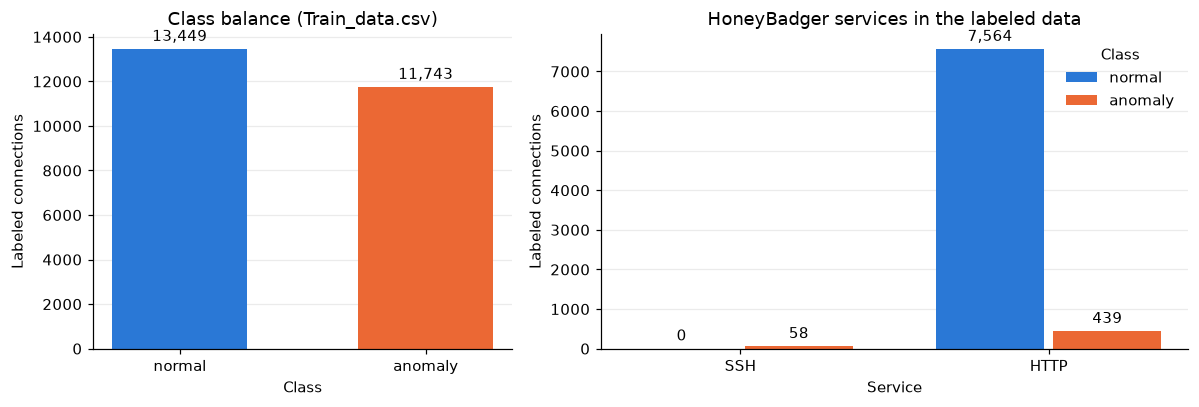

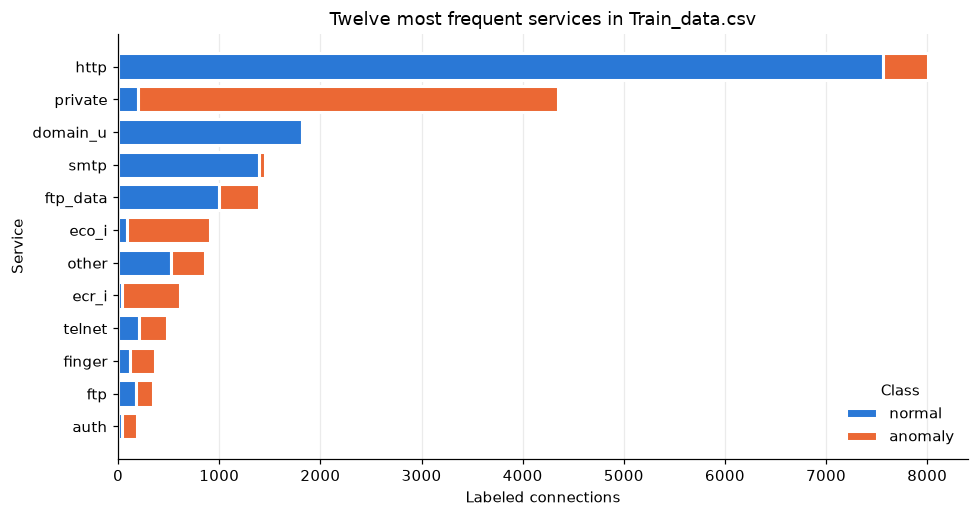

In [4]:
balance = train['class'].value_counts().reindex(CLASSES)
by_service = pd.crosstab(train['service'], train['class']).reindex(columns=CLASSES, fill_value=0)
honeypot_services = by_service.reindex(['ssh', 'http'], fill_value=0)
coverage = honeypot_services.assign(total=honeypot_services.sum(axis=1),
                                    unlabeled_test_rows=test['service'].value_counts().reindex(['ssh', 'http'], fill_value=0))
display(balance.to_frame('labeled connections').assign(share=(balance / balance.sum()).round(3)))
display(coverage)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={'width_ratios': [1, 1.4]})
ax1.bar(balance.index, balance.values, color=[COLORS[c] for c in balance.index], width=0.55)
for x, value in enumerate(balance.values):
    ax1.annotate(f'{value:,}', (x, value), ha='center', va='bottom', xytext=(0, 3), textcoords='offset points')
ax1.set(title='Class balance (Train_data.csv)', xlabel='Class', ylabel='Labeled connections')
ax1.grid(axis='x', visible=False)

positions = np.arange(len(honeypot_services))
width = 0.38
for offset, label in zip((-width / 2, width / 2), CLASSES):
    values = honeypot_services[label].to_numpy()
    ax2.bar(positions + offset, values, width - 0.03, color=COLORS[label], label=label)
    for x, value in zip(positions + offset, values):
        ax2.annotate(f'{value:,}', (x, value), ha='center', va='bottom', xytext=(0, 3), textcoords='offset points')
ax2.set_xticks(positions, ['SSH', 'HTTP'])
ax2.set(title='HoneyBadger services in the labeled data', xlabel='Service', ylabel='Labeled connections')
ax2.legend(title='Class', frameon=False)
ax2.grid(axis='x', visible=False)
fig.tight_layout()
plt.show()

top = by_service.loc[by_service.sum(axis=1).nlargest(12).index[::-1]]
fig, ax = plt.subplots(figsize=(9, 4.8))
left = np.zeros(len(top))
for label in CLASSES:
    ax.barh(top.index, top[label], left=left, color=COLORS[label], label=label, edgecolor='white', linewidth=2)
    left += top[label].to_numpy()
ax.set(title='Twelve most frequent services in Train_data.csv', xlabel='Labeled connections', ylabel='Service')
ax.legend(title='Class', frameon=False, loc='lower right')
ax.grid(axis='y', visible=False)
fig.tight_layout()
plt.show()

**What these counts allow.** Every labeled SSH connection is an anomaly; there are no normal SSH examples. On SSH we can measure how many anomalies are caught (recall), but not the false-alarm rate. HTTP has both classes, so both rates can be measured there, though HTTP anomalies are a small minority. Neither subset can tell us how a model behaves on HoneyBadger events. The feature definitions differ, and honeypot traffic contains almost no benign users.

## 4. Validation design

* **Grouped split.** Rows with an identical feature vector share a group, and a group never spans both partitions. Groups are shuffled with a fixed seed separately within each class and cut into five folds of roughly equal row counts, so each fold keeps the overall class balance. Fold 1 (about 20% of rows) is the validation partition. The fold assignment is written out explicitly, so it does not change between library versions.
* **No leakage.** The cell asserts that no feature vector is in both partitions.
* **Preprocessing inside the pipeline.** The one-hot encoder for `protocol_type`, `service` and `flag` is fitted on the training partition only. Values it has not seen are ignored.
* **Models.** A majority-class baseline, which always predicts the most common label, and a random forest, which is fast on CPU and needs no feature scaling.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder


def grouped_stratified_folds(groups, labels, n_folds=5, seed=SEED):
    # Fold number per row. Whole groups go to one fold; groups are shuffled within each
    # class (a group with mixed labels uses its alphabetically first most common label).
    frame = pd.DataFrame({'group': groups, 'label': np.asarray(labels)})
    group_label = frame.groupby('group')['label'].agg(lambda s: sorted(s.mode())[0])
    group_size = frame.groupby('group').size()
    rng = np.random.default_rng(seed)
    group_fold = {}
    for label in sorted(group_label.unique()):
        members = group_label.index[group_label == label].to_numpy()
        members = members[rng.permutation(len(members))]
        sizes = group_size.loc[members].to_numpy()
        starts = np.cumsum(sizes) - sizes            # rows placed before each group
        group_fold.update(zip(members, starts * n_folds // sizes.sum()))
    return frame['group'].map(group_fold).to_numpy()


X, y = train[features], train['class']
folds = grouped_stratified_folds(train_ids, y)
fit_idx, val_idx = np.flatnonzero(folds != 0), np.flatnonzero(folds == 0)
X_fit, X_val, y_fit, y_val = X.iloc[fit_idx], X.iloc[val_idx], y.iloc[fit_idx], y.iloc[val_idx]

shared = set(train_ids[fit_idx]) & set(train_ids[val_idx])
assert not shared, f'{len(shared)} feature vectors appear in both partitions'
print('Feature vectors shared by training and validation partitions: 0')
display(pd.DataFrame({'rows': [len(fit_idx), len(val_idx)],
                      'anomaly share': [y_fit.eq('anomaly').mean().round(3), y_val.eq('anomaly').mean().round(3)]},
                     index=['training partition', 'validation partition']))


def make_forest():
    encoder = ColumnTransformer([('categories', OneHotEncoder(handle_unknown='ignore'), categorical)],
                                remainder='passthrough')
    forest = RandomForestClassifier(n_estimators=200, min_samples_leaf=1, n_jobs=-1, random_state=SEED)
    return Pipeline([('encode', encoder), ('model', forest)])


def anomaly_report(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=CLASSES).ravel()
    return {'anomaly precision': precision_score(y_true, y_pred, pos_label='anomaly', zero_division=0),
            'anomaly recall': recall_score(y_true, y_pred, pos_label='anomaly', zero_division=0),
            'anomaly F1': f1_score(y_true, y_pred, pos_label='anomaly', zero_division=0),
            'accuracy': (tp + tn) / (tp + tn + fp + fn),
            'false alarms (normal flagged)': int(fp), 'missed anomalies': int(fn),
            'anomalies caught': int(tp), 'normal passed': int(tn)}


models = {'Majority baseline': DummyClassifier(strategy='most_frequent'), 'Random forest': make_forest()}
predictions, results = {}, {}
for name, estimator in models.items():
    estimator.fit(X_fit, y_fit)
    predictions[name] = estimator.predict(X_val)
    results[name] = anomaly_report(y_val, predictions[name])
results = pd.DataFrame(results)
rates = ['anomaly precision', 'anomaly recall', 'anomaly F1', 'accuracy']
display(results.apply(lambda row: row.map(('{:.4f}' if row.name in rates else '{:,.0f}').format), axis=1))

Feature vectors shared by training and validation partitions: 0


,rows,anomaly share
training partition,20153,0.466
validation partition,5039,0.466


,Majority baseline,Random forest
anomaly precision,0.0000,0.9991
anomaly recall,0.0000,0.9966
anomaly F1,0.0000,0.9979
accuracy,0.5338,0.9980
false alarms (normal flagged),0,2
missed anomalies,"2,349",8
anomalies caught,0,"2,341"
normal passed,"2,690","2,688"


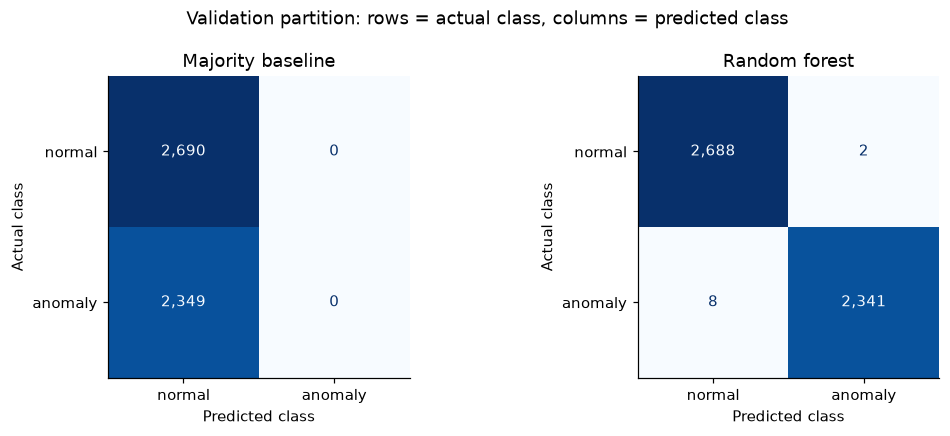

In plain language: the validation partition holds 2,349 anomalies and 2,690 normal connections.
The random forest caught 2,341 anomalies and missed 8 (recall 99.7%).
It raised 2 false alarms on normal traffic. When it says 'anomaly', it is right 99.9% of the time (precision).
The majority baseline predicts 'normal' for every row, so it catches 0 anomalies. Any useful detector must beat that.


In [6]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_val, y_pred, labels=CLASSES, cmap='Blues', colorbar=False, ax=ax,
                                            values_format=',')
    ax.set(title=name, xlabel='Predicted class', ylabel='Actual class')
    ax.grid(False)
fig.suptitle('Validation partition: rows = actual class, columns = predicted class')
fig.tight_layout()
plt.show()

r = results['Random forest']
n_anomalies = int(r['anomalies caught'] + r['missed anomalies'])
n_normal = int(r['normal passed'] + r['false alarms (normal flagged)'])
print(f"In plain language: the validation partition holds {n_anomalies:,} anomalies and {n_normal:,} normal connections.")
print(f"The random forest caught {int(r['anomalies caught']):,} anomalies and missed {int(r['missed anomalies']):,} "
      f"(recall {r['anomaly recall']:.1%}).")
print(f"It raised {int(r['false alarms (normal flagged)']):,} false alarms on normal traffic. When it says 'anomaly', "
      f"it is right {r['anomaly precision']:.1%} of the time (precision).")
print(f"The majority baseline predicts '{predictions['Majority baseline'][0]}' for every row, so it catches "
      f"{int(results.loc['anomalies caught', 'Majority baseline']):,} anomalies. Any useful detector must beat that.")

### Per-service results and stability

Overall scores can hide service-level gaps. The table below splits the validation partition by service. Then grouped 5-fold cross-validation shows how much the score moves when a different 20% is held out.

In [7]:
val_frame = X_val.assign(actual=y_val.to_numpy(), predicted=predictions['Random forest'])
val_frame['group'] = np.where(val_frame['service'].isin(['ssh', 'http']), val_frame['service'], 'all other services')
rows = {}
for group, part in val_frame.groupby('group'):
    report = anomaly_report(part['actual'], part['predicted'])
    rows[group] = {'rows': len(part), 'actual anomalies': int((part['actual'] == 'anomaly').sum()),
                   'actual normal': int((part['actual'] == 'normal').sum()),
                   'anomaly recall': report['anomaly recall'] if (part['actual'] == 'anomaly').any() else np.nan,
                   'false alarms': report['false alarms (normal flagged)'],
                   'missed anomalies': report['missed anomalies']}
service_table = pd.DataFrame.from_dict(rows, orient='index').reindex(['ssh', 'http', 'all other services'])
display(service_table.round({'anomaly recall': 3}))
print('SSH has no normal rows, so its false-alarm count is 0 by construction and says nothing about precision.')

fold_scores = []
for fold in range(5):
    a, b = np.flatnonzero(folds != fold), np.flatnonzero(folds == fold)
    assert not set(train_ids[a]) & set(train_ids[b])
    model = make_forest().fit(X.iloc[a], y.iloc[a])
    report = anomaly_report(y.iloc[b], model.predict(X.iloc[b]))
    fold_scores.append({'fold': fold + 1, **{k: report[k] for k in ['anomaly precision', 'anomaly recall', 'anomaly F1',
                                                                 'false alarms (normal flagged)', 'missed anomalies']}})
fold_scores = pd.DataFrame(fold_scores).set_index('fold')
display(fold_scores.agg(['mean', 'std', 'min', 'max']).round(4))

,rows,actual anomalies,actual normal,anomaly recall,false alarms,missed anomalies
ssh,12,12,0,1.000,0,0
http,1630,90,1540,0.989,0,1
all other services,3397,2247,1150,0.997,2,7


SSH has no normal rows, so its false-alarm count is 0 by construction and says nothing about precision.


,anomaly precision,anomaly recall,anomaly F1,false alarms (normal flagged),missed anomalies
mean,0.9990,0.9957,0.9974,2.4000,10.0000
std,0.0007,0.0009,0.0007,1.6733,2.1213
min,0.9979,0.9945,0.9962,1.0000,8.0000
max,0.9996,0.9966,0.9981,5.0000,13.0000


In [8]:
forest = models['Random forest']
names = forest.named_steps['encode'].get_feature_names_out()
importance = pd.Series(forest.named_steps['model'].feature_importances_, index=names)
importance.index = importance.index.str.replace('categories__', '').str.replace('remainder__', '')
display(importance.nlargest(12).round(4).to_frame('impurity importance'))
print('Impurity importance shows what the forest splits on, not causal evidence of an attack.')

,impurity importance
src_bytes,0.1385
dst_bytes,0.0883
flag_SF,0.0637
logged_in,0.0528
dst_host_srv_count,0.0515
same_srv_rate,0.0498
diff_srv_rate,0.0434
dst_host_diff_srv_rate,0.0363
count,0.0352
dst_host_same_srv_rate,0.0344


Impurity importance shows what the forest splits on, not causal evidence of an attack.


## 5. Predict the unlabeled test file

The model is refitted on all labeled rows and then predicts every row of `Test_data.csv`. The export keeps the original order: `test_row` is the zero-based row position in `Test_data.csv`. Two extra columns help interpret each prediction:

* `seen_in_training`: the identical feature vector occurs in `Train_data.csv`.
* `unseen_category`: the row has a `protocol_type`, `service` or `flag` value the model never saw.

The test file has no labels, so no metric is calculated on it.

In [9]:
final_model = make_forest().fit(X, y)
anomaly_column = list(final_model.classes_).index('anomaly')
unseen = np.zeros(len(test), dtype=bool)
for column in categorical:
    unseen |= ~test[column].isin(set(train[column])).to_numpy()

result = pd.DataFrame({
    'test_row': np.arange(len(test)),
    'predicted_class': final_model.predict(test[features]),
    'anomaly_probability': final_model.predict_proba(test[features])[:, anomaly_column].round(4),
    'seen_in_training': in_train,
    'unseen_category': unseen,
})
result.to_csv(PREDICTIONS_FILE, index=False)

check = pd.read_csv(PREDICTIONS_FILE)
assert len(check) == len(test) and check['test_row'].tolist() == list(range(len(test)))
assert check['predicted_class'].isin(CLASSES).all()
print(f'Saved {len(check):,} predictions to {PREDICTIONS_FILE} (one per Test_data.csv row, original order).')
display(result['predicted_class'].value_counts().to_frame('test rows'))
display(pd.crosstab(test['service'], result['predicted_class']).reindex(['ssh', 'http'], fill_value=0))
display(result.head())

Saved 22,544 predictions to ..\results\predictions\intrusion_predictions.csv (one per Test_data.csv row, original order).


,test rows
predicted_class,
normal,14175
anomaly,8369


predicted_class,anomaly,normal
service,,
ssh,26,0
http,836,7017


,test_row,predicted_class,anomaly_probability,seen_in_training,unseen_category
0,0,anomaly,1.000,False,False
1,1,anomaly,1.000,False,False
2,2,normal,0.000,False,False
3,3,anomaly,0.975,False,False
4,4,normal,0.335,False,False


In [10]:
# In Colab, this offers the predictions file as a browser download. Set to False to skip.
DOWNLOAD_IN_COLAB = True
if IN_COLAB and DOWNLOAD_IN_COLAB:
    from google.colab import files
    files.download(str(PREDICTIONS_FILE))
else:
    print(f'Predictions saved to {PREDICTIONS_FILE}.')

Predictions saved to ..\results\predictions\intrusion_predictions.csv.


## 6. Conclusion: what this means for HoneyBadger

**What the experiment shows.** The validation tables above measure how well a random forest separates the two labels *within this Kaggle dataset*, with duplicate feature vectors kept out of the validation partition. That is a benchmark result on recorded connection summaries. It is not evidence about live honeypot traffic.

**How the fields line up**

| Kaggle field(s) | HoneyBadger concept | Where in HoneyBadger |
|---|---|---|
| `service` (`ssh`, `http`) | the emulated service | `RawEvent.service`, `events.service` |
| `protocol_type` | transport (always TCP for both services) | implied by the listener |
| `num_failed_logins`, `logged_in`, `is_guest_login` | login attempts | SSH `auth` events and HTTP login POSTs carry `login_info` (username + `sha256:` hash); every SSH login is accepted |
| `count`, `srv_count`, `dst_host_count`, `dst_host_srv_count` | repeated connections from one source within a window | can be derived from `source_ip` + `timestamp` aggregation; not stored |
| `flag`, `serror_rate`, `rerror_rate` | TCP handshake outcome / errors | not captured; the SSH sensor only records the client version (`ssh_handshake`) |
| `duration`, `src_bytes`, `dst_bytes` | session length and volume | not captured |
| `class` (`normal`/`anomaly`) | ground truth | **no equivalent**; `technique_id` is a rule-based tag from `backend/mitre.py`, not a verified label |

**Missing from the Kaggle data:** source IP, timestamps, usernames and password hashes, shell commands, HTTP method/path/status/user agent, payload URLs, GeoIP and MITRE technique tags, which are the fields HoneyBadger stores. **Missing from HoneyBadger:** byte counts, durations, TCP flags and the window aggregates the Kaggle model depends on. A model trained here therefore cannot be applied to HoneyBadger events directly.

**Evidence needed to evaluate a model on real honeypot events**

1. An export of the `events` table (or the `/events` API) covering a fixed period, grouped into sessions by `source_ip`, ports and time.
2. Ground-truth labels for those sessions from manual review or a trusted second source. The rule-based `technique_id` is not ground truth.
3. Benign or known-scanner reference traffic. Nearly everything that reaches a honeypot is unsolicited, so a false-alarm rate needs an explicit definition of "normal".
4. A time-based split (train on earlier weeks, test on later ones) with sessions from one source kept in one partition.
5. Per-service counts large enough to report SSH and HTTP separately, with both classes present in each.

**Most important limitation.** The labeled SSH subset contains only anomalies. SSH recall can be estimated, but SSH false alarms and precision cannot, and SSH is a core HoneyBadger service.